## Imports and Data

In [428]:
import kagglehub
path = kagglehub.dataset_download("aparnashastry/building-permit-applications-data")

Using Colab cache for faster access to the 'building-permit-applications-data' dataset.


In [429]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [430]:
data=pd.read_csv(path + '/Building_Permits.csv')
df=data.copy()
data.head(2)

/tmp/ipykernel_721/3521776328.py:1: DtypeWarning: Columns (22,32) have mixed types. Specify dtype option on import or set low_memory=False.
  data=pd.read_csv(path + '/Building_Permits.csv')


,Permit Number,Permit Type,Permit Type Definition,Permit Creation Date,Block,Lot,Street Number,Street Number Suffix,Street Name,Street Suffix,...,Existing Construction Type,Existing Construction Type Description,Proposed Construction Type,Proposed Construction Type Description,Site Permit,Supervisor District,Neighborhoods - Analysis Boundaries,Zipcode,Location,Record ID
0,201505065519,4,sign - erect,05/06/2015,0326,023,140,NaN,Ellis,St,...,3.0,constr type 3,NaN,NaN,NaN,3.0,Tenderloin,94102.0,"(37.785719256680785, -122.40852313194863)",1380611233945
1,201604195146,4,sign - erect,04/19/2016,0306,007,440,NaN,Geary,St,...,3.0,constr type 3,NaN,NaN,NaN,3.0,Tenderloin,94102.0,"(37.78733980600732, -122.41063199757738)",1420164406718


## About Data

In [431]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198900 entries, 0 to 198899
Data columns (total 43 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   Permit Number                           198900 non-null  object 
 1   Permit Type                             198900 non-null  int64  
 2   Permit Type Definition                  198900 non-null  object 
 3   Permit Creation Date                    198900 non-null  object 
 4   Block                                   198900 non-null  object 
 5   Lot                                     198900 non-null  object 
 6   Street Number                           198900 non-null  int64  
 7   Street Number Suffix                    2216 non-null    object 
 8   Street Name                             198900 non-null  object 
 9   Street Suffix                           196132 non-null  object 
 10  Unit                                    2947

In [432]:
df.isnull().sum()

,0
Permit Number,0
Permit Type,0
Permit Type Definition,0
Permit Creation Date,0
Block,0
Lot,0
Street Number,0
Street Number Suffix,196684
Street Name,0
Street Suffix,2768


In [433]:
(df.isnull().sum()/df.shape[0])*100

,0
Permit Number,0.000000
Permit Type,0.000000
Permit Type Definition,0.000000
Permit Creation Date,0.000000
Block,0.000000
Lot,0.000000
Street Number,0.000000
Street Number Suffix,98.885872
Street Name,0.000000
Street Suffix,1.391654


## Dropping unfillable columns

In [434]:
col_to_Remove=['Street Number Suffix','Unit','Unit Suffix','Completed Date','Structural Notification',
               'Voluntary Soft-Story Retrofit','Fire Only Permit','TIDF Compliance','Site Permit']

df.drop(columns=col_to_Remove,inplace=True)
df.head(3)

,Permit Number,Permit Type,Permit Type Definition,Permit Creation Date,Block,Lot,Street Number,Street Name,Street Suffix,Description,...,Plansets,Existing Construction Type,Existing Construction Type Description,Proposed Construction Type,Proposed Construction Type Description,Supervisor District,Neighborhoods - Analysis Boundaries,Zipcode,Location,Record ID
0,201505065519,4,sign - erect,05/06/2015,0326,023,140,Ellis,St,"ground fl facade: to erect illuminated, electr...",...,2.0,3.0,constr type 3,NaN,NaN,3.0,Tenderloin,94102.0,"(37.785719256680785, -122.40852313194863)",1380611233945
1,201604195146,4,sign - erect,04/19/2016,0306,007,440,Geary,St,remove (e) awning and associated signs.,...,2.0,3.0,constr type 3,NaN,NaN,3.0,Tenderloin,94102.0,"(37.78733980600732, -122.41063199757738)",1420164406718
2,201605278609,3,additions alterations or repairs,05/27/2016,0595,203,1647,Pacific,Av,installation of separating wall,...,2.0,1.0,constr type 1,1.0,constr type 1,3.0,Russian Hill,94109.0,"(37.7946573324287, -122.42232562979227)",1424856504716


In [435]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198900 entries, 0 to 198899
Data columns (total 34 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   Permit Number                           198900 non-null  object 
 1   Permit Type                             198900 non-null  int64  
 2   Permit Type Definition                  198900 non-null  object 
 3   Permit Creation Date                    198900 non-null  object 
 4   Block                                   198900 non-null  object 
 5   Lot                                     198900 non-null  object 
 6   Street Number                           198900 non-null  int64  
 7   Street Name                             198900 non-null  object 
 8   Street Suffix                           196132 non-null  object 
 9   Description                             198610 non-null  object 
 10  Current Status                          1989

## Filling Null Values

In [436]:
df['Permit Type']=df['Permit Type'].astype('object')
df['Existing Construction Type']=df['Existing Construction Type'].astype('object')
df['Proposed Construction Type']=df['Proposed Construction Type'].astype('object')
df['Supervisor District']=df['Supervisor District'].astype('object')
df['Zipcode']=df['Zipcode'].astype('object')

In [437]:
obj_cols=df.select_dtypes('object').columns.tolist()
obj_cols

['Permit Number',
 'Permit Type',
 'Permit Type Definition',
 'Permit Creation Date',
 'Block',
 'Lot',
 'Street Name',
 'Street Suffix',
 'Description',
 'Current Status',
 'Current Status Date',
 'Filed Date',
 'Issued Date',
 'First Construction Document Date',
 'Permit Expiration Date',
 'Existing Use',
 'Proposed Use',
 'Existing Construction Type',
 'Existing Construction Type Description',
 'Proposed Construction Type',
 'Proposed Construction Type Description',
 'Supervisor District',
 'Neighborhoods - Analysis Boundaries',
 'Zipcode',
 'Location']

In [438]:
num_cols=df.select_dtypes('float64').columns.tolist()
num_cols

['Number of Existing Stories',
 'Number of Proposed Stories',
 'Estimated Cost',
 'Revised Cost',
 'Existing Units',
 'Proposed Units',
 'Plansets']

In [439]:
for col in obj_cols:
  df[col]=df[col].fillna(df[col].mode()[0])

for column in num_cols:
  df[column]=df[column].fillna(df[column].median())

/tmp/ipykernel_721/1364042357.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col]=df[col].fillna(df[col].mode()[0])


In [440]:
df['Permit Type']=df['Permit Type'].astype('float64')
df['Existing Construction Type']=df['Existing Construction Type'].astype('float64')
df['Proposed Construction Type']=df['Proposed Construction Type'].astype('float64')
df['Supervisor District']=df['Supervisor District'].astype('float64')
df['Zipcode']=df['Zipcode'].astype('float64')

In [441]:
df.isnull().sum()

,0
Permit Number,0
Permit Type,0
Permit Type Definition,0
Permit Creation Date,0
Block,0
Lot,0
Street Number,0
Street Name,0
Street Suffix,0
Description,0


## Dealing Outliers

In [442]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198900 entries, 0 to 198899
Data columns (total 34 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   Permit Number                           198900 non-null  object 
 1   Permit Type                             198900 non-null  float64
 2   Permit Type Definition                  198900 non-null  object 
 3   Permit Creation Date                    198900 non-null  object 
 4   Block                                   198900 non-null  object 
 5   Lot                                     198900 non-null  object 
 6   Street Number                           198900 non-null  int64  
 7   Street Name                             198900 non-null  object 
 8   Street Suffix                           198900 non-null  object 
 9   Description                             198900 non-null  object 
 10  Current Status                          1989

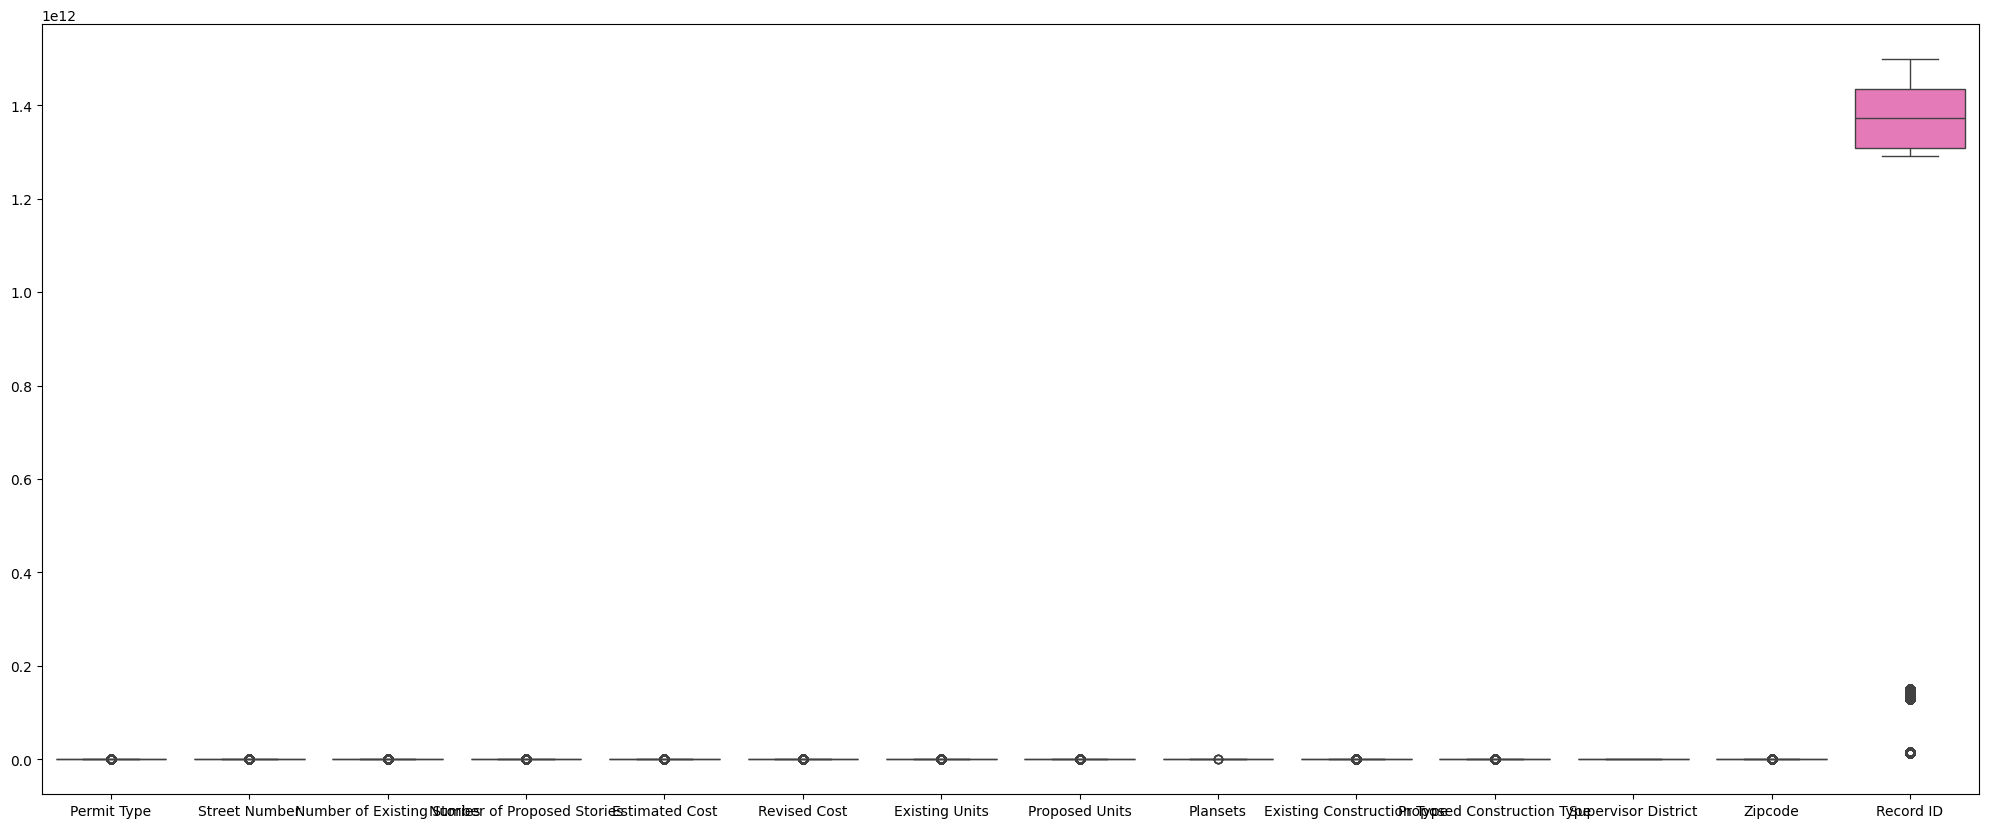

In [443]:
plt.figure(figsize=(25,10))
sns.boxplot(df)
plt.show()

In [444]:
# only record id has outliers
Q1=df['Record ID'].quantile(0.25)
Q3=df['Record ID'].quantile(0.75)
IQR=Q3-Q1
low=Q1-(1.5*IQR)
high=Q3+(1.5*IQR)
df=df[(df['Record ID'] >= low) & (df['Record ID'] <= high)]

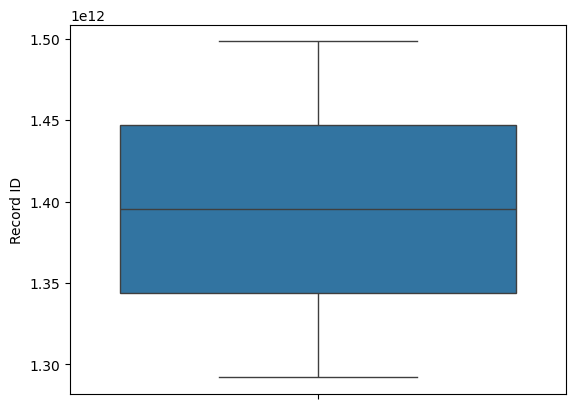

In [445]:
sns.boxplot(df['Record ID'])
plt.show()

## Duplicates

In [446]:
df.duplicated().sum()

np.int64(0)

## EDA

In [447]:
df.describe()

,Permit Type,Street Number,Number of Existing Stories,Number of Proposed Stories,Estimated Cost,Revised Cost,Existing Units,Proposed Units,Plansets,Existing Construction Type,Proposed Construction Type,Supervisor District,Zipcode,Record ID
count,161995.000000,161995.000000,161995.000000,161995.000000,1.619950e+05,1.619950e+05,161995.000000,161995.000000,161995.000000,161995.000000,161995.000000,161995.000000,161995.000000,1.619950e+05
mean,7.511818,1099.791216,4.658863,4.698512,1.439832e+05,1.369128e+05,11.416507,12.431594,1.387722,4.338671,4.348196,6.085719,94115.522806,1.395367e+12
std,1.473777,1137.890095,6.935331,6.957345,3.483184e+06,3.827812e+06,65.792453,66.676282,22.377755,1.399705,1.393861,2.829208,9.548144,5.953602e+10
min,1.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,94102.000000,1.292110e+12
25%,8.000000,236.000000,2.000000,2.000000,5.000000e+03,1.000000e+00,1.000000,1.000000,0.000000,5.000000,5.000000,4.000000,94109.000000,1.343856e+12
50%,8.000000,680.000000,3.000000,3.000000,1.100000e+04,7.000000e+03,1.000000,2.000000,2.000000,5.000000,5.000000,6.000000,94114.000000,1.395568e+12
75%,8.000000,1614.500000,3.000000,3.000000,2.500000e+04,2.500000e+04,2.000000,3.000000,2.000000,5.000000,5.000000,8.000000,94122.000000,1.446938e+12
max,8.000000,8400.000000,78.000000,78.000000,5.379586e+08,7.805000e+08,1907.000000,1911.000000,9000.000000,5.000000,5.000000,11.000000,94158.000000,1.498342e+12


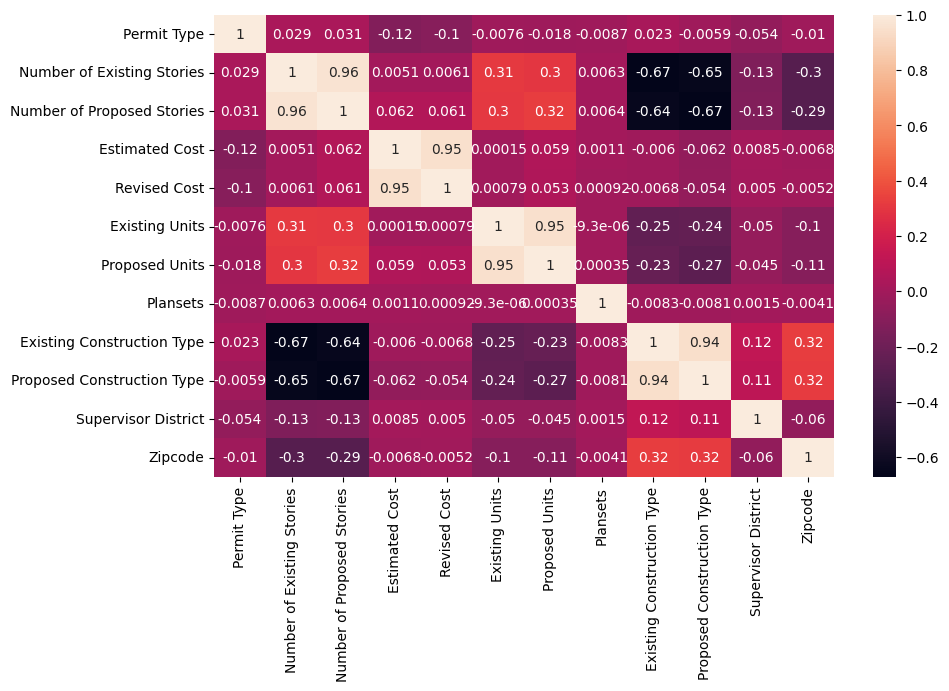

In [448]:
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes('float64').corr(),annot=True)
plt.show()

In [449]:
# Shows that the data is highly coorelated and all the numerical columns are correlated

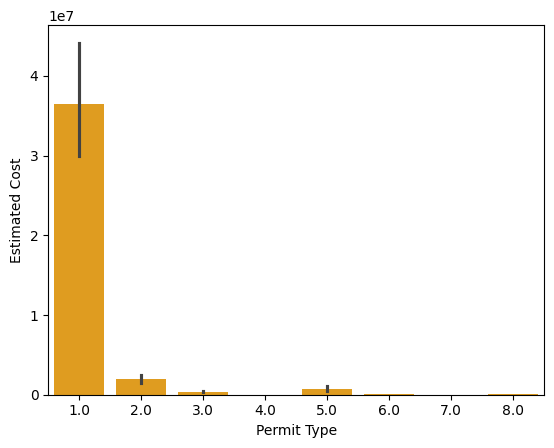

In [450]:
# Plotting Estimated cost and Permit type
sns.barplot(x=df['Permit Type'],y=df['Estimated Cost'],color='orange')
plt.show()

In [451]:
# thus we got to know permit type 1 has highest estimated cost

## Encoding the data

In [452]:
df.select_dtypes('object').head(1)

,Permit Number,Permit Type Definition,Permit Creation Date,Block,Lot,Street Name,Street Suffix,Description,Current Status,Current Status Date,Filed Date,Issued Date,First Construction Document Date,Permit Expiration Date,Existing Use,Proposed Use,Existing Construction Type Description,Proposed Construction Type Description,Neighborhoods - Analysis Boundaries,Location
0,201505065519,sign - erect,05/06/2015,0326,023,Ellis,St,"ground fl facade: to erect illuminated, electr...",expired,12/21/2017,05/06/2015,11/09/2015,11/09/2015,11/03/2016,tourist hotel/motel,1 family dwelling,constr type 3,wood frame (5),Tenderloin,"(37.785719256680785, -122.40852313194863)"


In [453]:
"""
Columns like Current Status Date	Filed Date	Issued Date First Construction Document Date	Permit Expiration Date
are not important as the column 'Current Status' gives us the whole idea of the permit.

Also the the column Description and Permit Number is not usable with the context of our model do we would drop these columns.

Street Name would not be suitable to be encoded as we would encode the according to the suffix

The Location column would not be much hepful as we have column Neighborhoods - Analysis Boundaries which can be encoded based on locality"""
column=['Current Status Date','Filed Date','Issued Date','First Construction Document Date','Permit Expiration Date','Description','Permit Number','Street Name','Location']
df.drop(columns=column,axis=1,inplace=True)

In [454]:
df.select_dtypes('object').head(3)

,Permit Type Definition,Permit Creation Date,Block,Lot,Street Suffix,Current Status,Existing Use,Proposed Use,Existing Construction Type Description,Proposed Construction Type Description,Neighborhoods - Analysis Boundaries
0,sign - erect,05/06/2015,0326,023,St,expired,tourist hotel/motel,1 family dwelling,constr type 3,wood frame (5),Tenderloin
1,sign - erect,04/19/2016,0306,007,St,issued,tourist hotel/motel,1 family dwelling,constr type 3,wood frame (5),Tenderloin
2,additions alterations or repairs,05/27/2016,0595,203,Av,withdrawn,retail sales,retail sales,constr type 1,constr type 1,Russian Hill


In [455]:
# Lets first find columns that can be one Hot Encoded
OHE_Col=['Permit Type Definition','Street Suffix','Current Status','Existing Use',
         'Proposed Use','Existing Construction Type Description','Proposed Construction Type Description']
df=pd.get_dummies(df,columns=OHE_Col,dtype=int)

In [456]:
df.select_dtypes('object').head(3)

,Permit Creation Date,Block,Lot,Neighborhoods - Analysis Boundaries
0,05/06/2015,0326,023,Tenderloin
1,04/19/2016,0306,007,Tenderloin
2,05/27/2016,0595,203,Russian Hill


In [457]:
df['Neighborhoods - Analysis Boundaries'].unique()

array(['Tenderloin', 'Russian Hill', 'Nob Hill', 'Potrero Hill',
       'Inner Sunset', 'Bayview Hunters Point', 'Lone Mountain/USF',
       'Castro/Upper Market', 'Noe Valley', 'Marina', 'Mission',
       'Sunset/Parkside', 'Outer Richmond',
       'Financial District/South Beach', 'Bernal Heights', 'Chinatown',
       'Inner Richmond', 'Pacific Heights', 'Oceanview/Merced/Ingleside',
       'Outer Mission', 'Portola', 'Mission Bay', 'Visitacion Valley',
       'West of Twin Peaks', 'South of Market', 'Haight Ashbury',
       'Excelsior', 'North Beach', 'Glen Park', 'Western Addition',
       'Hayes Valley', 'Treasure Island', 'Twin Peaks',
       'Presidio Heights', 'Lincoln Park', 'Lakeshore', 'Seacliff',
       'Japantown', 'Golden Gate Park', 'McLaren Park', 'Presidio'],
      dtype=object)

In [458]:
# lets tier these locations based on standard of living using the data from the internet
neighborhood_tiers = {
    "Tenderloin": 5,
    "Russian Hill": 1,
    "Nob Hill": 2,
    "Potrero Hill": 2,
    "Inner Sunset": 3,
    "Bayview Hunters Point": 5,
    "Lone Mountain/USF": 3,
    "Castro/Upper Market": 3,
    "Noe Valley": 2,
    "Marina": 2,
    "Mission": 4,
    "Sunset/Parkside": 4,
    "Outer Richmond": 4,
    "Financial District/South Beach": 2,
    "Bernal Heights": 3,
    "Chinatown": 4,
    "Inner Richmond": 3,
    "Pacific Heights": 1,
    "Oceanview/Merced/Ingleside": 4,
    "Outer Mission": 4,
    "Portola": 4,
    "Mission Bay": 2,
    "Visitacion Valley": 5,
    "West of Twin Peaks": 2,
    "South of Market": 4,
    "Haight Ashbury": 3,
    "Excelsior": 4,
    "North Beach": 4,
    "Glen Park": 2,
    "Western Addition": 4,
    "Hayes Valley": 3,
    "Treasure Island": 5,
    "Twin Peaks": 3,
    "Presidio Heights": 1,
    "Lincoln Park": 1,
    "Lakeshore": 4,
    "Seacliff": 1,
    "Japantown": 3,
    "Golden Gate Park": 0,  # 0 indicates Public Park / Non-Residential
    "McLaren Park": 0,     # 0 indicates Public Park / Non-Residential
    "Presidio": 2
}
df['neighbourhood_encoded']=df['Neighborhoods - Analysis Boundaries'].map(neighborhood_tiers)
df.drop(columns=['Neighborhoods - Analysis Boundaries'],inplace=True)

In [459]:
df.select_dtypes('object').head(3)

,Permit Creation Date,Block,Lot
0,05/06/2015,0326,023
1,04/19/2016,0306,007
2,05/27/2016,0595,203


In [460]:
# For encoding the date we would directly distribute the date into separate columns eg: day,Month,Year,Day of the week
df['Permit Creation Date']=pd.to_datetime(df['Permit Creation Date'])
df['day']=df['Permit Creation Date'].dt.day
df['month']=df['Permit Creation Date'].dt.month
df['year']=df['Permit Creation Date'].dt.year
df['quater']=df['Permit Creation Date'].dt.quarter
df.drop(columns=['Permit Creation Date'],inplace=True)

In [461]:
# for column Block and Lot we would target encode them according to the Estimated Cost
from sklearn.preprocessing import TargetEncoder
TE=TargetEncoder()
encoded_bl=TE.fit_transform(df[['Block','Lot']],df['Estimated Cost'])
df[['Block_encoded','Lot_encoded']] = encoded_bl

# Drop original string columns so they do not cause errors during scaling
df.drop(columns=['Block','Lot'], inplace=True)

In [462]:
df.head(1)

,Permit Type,Street Number,Number of Existing Stories,Number of Proposed Stories,Estimated Cost,Revised Cost,Existing Units,Proposed Units,Plansets,Existing Construction Type,...,Proposed Construction Type Description_constr type 3,Proposed Construction Type Description_constr type 4,Proposed Construction Type Description_wood frame (5),neighbourhood_encoded,day,month,year,quater,Block_encoded,Lot_encoded
0,4.0,140,6.0,3.0,4000.0,4000.0,143.0,2.0,2.0,3.0,...,0,0,1,5,6,5,2015,2,44879.033182,70745.498324


In [463]:
df.shape

(161995, 261)

## Scaling the data

In [464]:
# NOw we would scale our data as unequal data may affect our model performance in a bad way

In [465]:
# StandardScaler helps to convert our data into mean centric

standard scaler = (X$_{i}$ - X$_{mean}$) / standard_dev(X)

In [466]:
# First lets divide the data into X(features) and y(Output)
X=df.drop(columns=['Estimated Cost'],axis=1)
y=df['Estimated Cost']

In [467]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
scaled_X=sc.fit_transform(X)

In [470]:
scaled_X

array([[-2.3828764 , -0.84348584,  0.1933781 , ..., -0.43859039,
        -0.23218698, -0.41590686],
       [-2.3828764 , -0.57983917,  0.33756776, ..., -0.43859039,
        -0.17114687, -0.11182496],
       [-3.06140707,  0.48089923,  0.1933781 , ..., -0.43859039,
        -0.3097944 , -0.11017822],
       ...,
       [ 0.33124628,  0.41147228, -0.23919088, ...,  1.36453497,
        -0.35132417, -0.34712902],
       [ 0.33124628, -0.26785729, -0.23919088, ...,  1.36453497,
        -0.31309987, -0.26184431],
       [ 0.33124628, -0.23006793, -0.23919088, ...,  1.36453497,
         1.85083771, -0.05299464]])

## Saving CSV

In [471]:
try:
  df.to_csv('SA_Building_Permit_Application_Cleaned.csv')
except ValueError:
  print("Enter correct value")
else:
  print("File saved successfully")


File saved successfully
